# Progetto: Filtro Anti-Hater per Social Network

### di Lavinia Solimani

Per questo progetto, il task da affrontare è una classificazione binaria multi-label con 6 classi non mutuamente esclusive. Il dataset utilizzato contiene circa 160.000 commenti, i quali possono essere etichettati con una, più di una, o nessuna di queste categorie:

1. Toxic (Tossico)
2. Severely Toxic (Super Tossico)
3. Obscene (Osceno)
4. Threat (Minaccia)
5. Insult (Insulto)
6. Identity Hate (Odio basato sull’identità)

Costruiremo un modello a reti neurali ricorrenti che come output restituirà, per ogni commento, un vettore di 6 elementi con valori binari, dove 1 indica la presenza della label corrispondente e 0 la sua assenza.

In [4]:
# No warnings
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [5]:
!pip install iterative-stratification

In [6]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.6 MB/s eta 0:00:00


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, precision_recall_curve,
                             classification_report, hamming_loss)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils import clip_grad_norm_
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import optuna
import inspect

In [8]:
# Seed for reproducibility
RANDOM_SEED = 42

# Device: GPU if available, else CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device currently in use: {device}')

# Figure style
sns.set_theme(style = 'whitegrid')

Device currently in use: cuda


Definiamo le costanti.

In [9]:
USE_UNDERSAMPLING = False
CLEAN_TO_INJURIOUS_RATIO = 3.0  # Ratio of clean and injurious comments in dataset
MAX_WORDS = 20000   # Maximum length of vocabulary
MAX_LEN = 60    # Maximum length of each token
BATCH_SIZE = 256
MODEL_PATH = 'best_toxic_rnn.pt'  # Path to store optimised model

## 1. Analisi Esplorativa del Dataset

In [10]:
df = pd.read_csv('Filter_Toxic_Comments_dataset.csv', sep = ',')
df.head(10)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,sum_injurious
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0
5,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,4
7,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0
8,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0
9,alignment on this subject and which are contra...,0,0,0,0,0,0,0


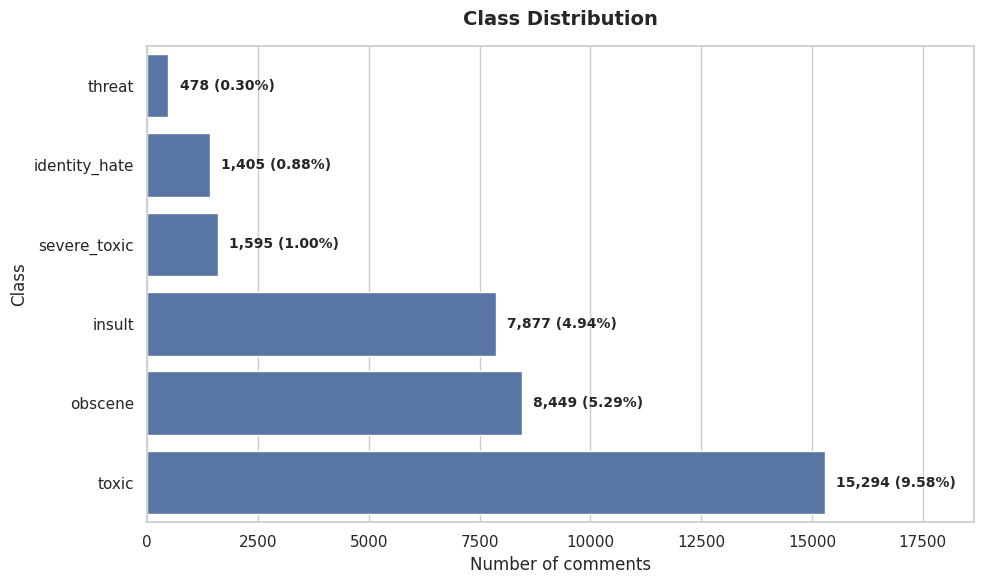

In [11]:
labels = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Calculate counts and percentages
counts = df[labels].sum().sort_values(ascending = True)
percentages = (counts / len(df)) * 100

# Plot class distribution
plt.figure(figsize = (10, 6))
ax = sns.barplot(x = counts.values, y = counts.index)

for i, (count, percentage) in zip(ax.patches, zip(counts.values, percentages.values)):
    width = i.get_width()
    ax.annotate(f'{count:,} ({percentage:.2f}%)',
                (width, i.get_y() + i.get_height() / 2.),
                ha = 'left',
                va = 'center',
                xytext = (8, 0),
                textcoords = 'offset points',
                fontsize = 10,
                fontweight = 'bold')

plt.title('Class Distribution', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Number of comments', fontsize = 12)
plt.ylabel('Class', fontsize = 12)
plt.xlim(0, max(counts.values) * 1.22)

plt.tight_layout()
plt.show()

Poiché, prevedibilmente, i commenti della classe di gravità più lieve, ovvero "toxic", sono molto più frequenti di quelli appartenenti alle altre classi, prima di procedere con la costruzione del modello dovremo necessariamente adottare un metodo per bilanciare le classi.

Analizziamo intanto il dataset verificando quanto segue:

- Dimensione del dataset;
- Numero di commenti per ogni label;
- Numero di commenti con 0-6 label;
- Numero di commenti completamente neutri;
- Commenti duplicati.

In [12]:
print('Dataset shape:', df.shape)

print('\nPositive examples per label:')
print(df[labels].sum().sort_values(ascending = False))

print('\nComments by number of active labels:')
df['num_labels'] = df[labels].sum(axis = 1)
label_dist = df['num_labels'].value_counts().sort_index()
for labels_count, num_comments in label_dist.items():
    percentage = (num_comments / len(df)) * 100
    print(f'{labels_count} labels: {num_comments:7} ({percentage:.2f}%)')

print('\nCompletely clean comments:',
      int((df[labels].sum(axis = 1) == 0).sum()))

print('\nDuplicate comments:',
      int(df['comment_text'].duplicated().sum()))

Dataset shape: (159571, 8)

Positive examples per label:
toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64

Comments by number of active labels:
0 labels:  143346 (89.83%)
1 labels:    6360 (3.99%)
2 labels:    3480 (2.18%)
3 labels:    4209 (2.64%)
4 labels:    1760 (1.10%)
5 labels:     385 (0.24%)
6 labels:      31 (0.02%)

Completely clean comments: 143346

Duplicate comments: 0


La distribuzione mostra che il dataset è sbilanciato non solo per quanto riguarda le categorie in cui i commenti negativi ricadono, ma anche da un punto di vista di proporzione tra commenti dannosi e commenti neutri.

In fase di preprocessing dei dati, utilizzeremo tecniche di bilanciamento basandoci su quelle illustrate in [questo articolo](https://www.geeksforgeeks.org/deep-learning/handling-class-imbalance-in-pytorch/).

## 2. Preprocessing dei dati

Implementeremo i seguenti step di preprocessing:

1. **Split in set di addestramento, di validazione e di test**, usando una stratificazione specifica per dati multi-label;
2. **Undersampling solo sul training set** (solo se necessario);
3. **Pulizia del testo**;
4. **Tokenizzazione e costruzione del vocabolario** sul set di addestramento;
5. **Encoding, padding** e definizione di **Dataset e DataLoader**.


### 2.1. Split in set di addestramento, di validazione e di test

Poiché stiamo gestendo dati multi-label, il classico **stratify** del metodo **train_test_split** non è adatto a garantire il bilanciamento delle classi. Pertanto, useremo la classe [**MultilabelStratifiedShuffleSplit**](https://github.com/trent-b/iterative-stratification?utm_source=chatgpt.com), che ovvia a questo problema.

Inoltre, definiamo una funzione che ritorni la distribuzione in percentuale delle label in ciascun set, per monitorare il bilanciamento delle classi.

In [13]:
# ============================================================
# TRAIN / VAL / TEST SPLIT (70% / 15% / 15%)
# ============================================================

y = df[labels].to_numpy(dtype = np.int8)
indices = np.arange(len(df))

# First split: 70% train set / 30% temp set
splitter_1 = MultilabelStratifiedShuffleSplit(n_splits = 1,
                                              test_size = .3,
                                              random_state = RANDOM_SEED)

train_idx, temp_idx = next(splitter_1.split(indices, y))

# Second split: 15% validation set / 15% test set
splitter_2 = MultilabelStratifiedShuffleSplit(n_splits = 1,
                                              test_size = .5,
                                              random_state = RANDOM_SEED)

val_rel_idx, test_rel_idx = next(splitter_2.split(temp_idx, y[temp_idx]))

val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()

print(f'TRAIN SET:      {len(train_df):,} ({len(train_df) / len(df):.2%})')
print(f'VALIDATION SET: {len(val_df):,}  ({len(val_df) / len(df):.2%})')
print(f'TEST SET:       {len(test_df):,}  ({len(test_df) / len(df):.2%})')


def print_label_distribution(name, frame):
    counts = frame[labels].sum()
    percentages = (counts / len(frame)) * 100

    print(f'\n{name}')
    for label in labels:
        print(f'{label}: {int(counts[label]):,d} ({percentages[label]:.2f}%)')


print_label_distribution('FULL DATASET', df)
print_label_distribution('TRAIN SET', train_df)
print_label_distribution('VALIDATION SET', val_df)
print_label_distribution('TEST SET', test_df)

TRAIN SET:      111,699 (70.00%)
VALIDATION SET: 23,936  (15.00%)
TEST SET:       23,936  (15.00%)

FULL DATASET
toxic: 15,294 (9.58%)
severe_toxic: 1,595 (1.00%)
obscene: 8,449 (5.29%)
threat: 478 (0.30%)
insult: 7,877 (4.94%)
identity_hate: 1,405 (0.88%)

TRAIN SET
toxic: 10,706 (9.58%)
severe_toxic: 1,116 (1.00%)
obscene: 5,914 (5.29%)
threat: 335 (0.30%)
insult: 5,514 (4.94%)
identity_hate: 983 (0.88%)

VALIDATION SET
toxic: 2,294 (9.58%)
severe_toxic: 240 (1.00%)
obscene: 1,267 (5.29%)
threat: 71 (0.30%)
insult: 1,182 (4.94%)
identity_hate: 211 (0.88%)

TEST SET
toxic: 2,294 (9.58%)
severe_toxic: 239 (1.00%)
obscene: 1,268 (5.30%)
threat: 72 (0.30%)
insult: 1,181 (4.93%)
identity_hate: 211 (0.88%)


### 2.2. Undersampling

Step opzionale, solo nel caso in cui si abbiano limitate disponibilità di calcolo e si renda necessario ridurre la dimensionalità del dataset.

In [14]:
# ============================================================
# UNDERSAMPLING OF MAJORITY CLASS
# ============================================================

if USE_UNDERSAMPLING:
    train_injurious = train_df[train_df['sum_injurious'] > 0]
    train_clean = train_df[train_df['sum_injurious'] == 0]

    n_clean = min(len(train_clean), int(len(train_injurious) * CLEAN_TO_INJURIOUS_RATIO))

    train_clean_sampled = train_clean.sample(n = n_clean, random_state = RANDOM_SEED)

    train_df = pd.concat([train_injurious, train_clean_sampled], axis = 0).sample(
        frac = 1, random_state = RANDOM_SEED).reset_index(drop = True)

    print('\nTraining-only undersampling enabled.')
    print(f'Train size after undersampling: {len(train_df):,}')
else:
    print('\nTraining-only undersampling disabled: all training examples retained.')


Training-only undersampling disabled: all training examples retained.


### 2.3. Pulizia del testo

In [15]:
# ============================================================
# DATA CLEANING
# ============================================================

def clean_text(text):

  """
  Function for text cleaning.
  """

  # 1. Check if text is a string
  if not isinstance(text, str):
        return ''

  # 2. Convert all to lowercase
  text = text.lower()

  # 3. Remove URLs, HTML tags, user mentions and hashtags
  text = re.sub(r'http\S+|www\S+|https\S+', '', text)
  text = re.sub(r'\@\w+|\#', '', text)
  text = re.sub(r'<.*?>', '', text)

  # 4. Remove special characters, numbers and punctuation
  text = re.sub(r'[^a-zA-Z\s]', '', text)

  # 5. Remove extra spaces
  text = re.sub(r'\s+', ' ', text).strip()
  return text


# ============================================================
# APPLY CLEAN TEXT FUNCTION TO TRAIN, VALIDATION AND TEST SET
# ============================================================
train_df['cleaned_text'] = train_df['comment_text'].apply(clean_text)
val_df['cleaned_text'] = val_df['comment_text'].apply(clean_text)
test_df['cleaned_text'] = test_df['comment_text'].apply(clean_text)

X_train = train_df['cleaned_text'].astype(str).tolist()
X_val = val_df['cleaned_text'].astype(str).tolist()
X_test = test_df['cleaned_text'].astype(str).tolist()

y_train = train_df[labels].to_numpy(dtype = np.float32)
y_val = val_df[labels].to_numpy(dtype = np.float32)
y_test = test_df[labels].to_numpy(dtype = np.float32)

print('Final data shapes:')
print(f'X_train = {len(X_train)}, y_train = {y_train.shape}')
print(f'X_val   = {len(X_val)},  y_val   = {y_val.shape}')
print(f'X_test  = {len(X_test)},  y_test  = {y_test.shape}')

Final data shapes:
X_train = 111699, y_train = (111699, 6)
X_val   = 23936,  y_val   = (23936, 6)
X_test  = 23936,  y_test  = (23936, 6)


### 2.4. Tokenizzazione

In [16]:
# ============================================================
# TOKENISATION AND ENCODING
# ============================================================

def build_vocab(texts, max_words):

  """
  This function builds a vocabulary using the words with the highest frequency
  from a given text.
  """

  counter = Counter()
  for text in texts:
    counter.update(text.split())

  # Index 0 for padding, index 1 for unknown words
  vocab = {'<PAD>': 0, '<UNK>': 1}

  for word, _ in counter.most_common(max_words - 2):  # -2 for PAD and UNK
    vocab[word] = len(vocab)
  return vocab


# Build vocabulary with ONLY train set data
vocab = build_vocab(X_train, MAX_WORDS)

print(f'Vocabulary dimension: {len(vocab):,}')

Vocabulary dimension: 20,000


In [17]:
def encode_text(text, vocab, max_len):

  """
  This function converts text in numerical sequences of fixed length.
  """

  tokens = text.split()

  # Index if word exists, else 1 ('<UNK>')
  indices = [vocab.get(word, vocab['<UNK>']) for word in tokens]

  # Truncation and padding
  if len(indices) < max_len:
    indices += [vocab['<PAD>']] * (max_len - len(indices))
  else:
    indices = indices[: max_len]
  return indices


X_train_encoded = np.array([encode_text(text, vocab, MAX_LEN) for text in X_train])
X_val_encoded = np.array([encode_text(text, vocab, MAX_LEN) for text in X_val])
X_test_encoded = np.array([encode_text(text, vocab, MAX_LEN) for text in X_test])

### 2.5. Dataset e DataLoader PyTorch

In [18]:
# ============================================================
# DATASET PYTORCH
# ============================================================

class ToxicDataset(Dataset):

    """PyTorch Dataset for multi-label toxic-comment classification."""

    def __init__(self, encoded_texts, labels):
        self.X = torch.from_numpy(encoded_texts).long()
        self.y = torch.from_numpy(labels).float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = ToxicDataset(X_train_encoded, y_train)
val_ds = ToxicDataset(X_val_encoded, y_val)
test_ds = ToxicDataset(X_test_encoded, y_test)


# ============================================================
# DATALOADER PYTORCH
# ============================================================

loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_SEED)

train_loader = DataLoader(train_ds, batch_size = BATCH_SIZE,
                          shuffle = True, generator = loader_generator)
val_loader = DataLoader(val_ds, batch_size = BATCH_SIZE, shuffle = False)
test_loader = DataLoader(test_ds, batch_size = BATCH_SIZE, shuffle = False)

print(f'Train: {len(train_ds):,} | '
      f'Val: {len(val_ds):,} | '
      f'Test: {len(test_ds):,}')

Train: 111,699 | Val: 23,936 | Test: 23,936


## 3. Modello

Poiché il modello dovrà catturare le dipendenze a lungo termine tra le parole nei commenti, esso sarà basato su un'architettura ricorrente. Utilizzeremo un **Gated Recurrent Unit (GRU)**, in quanto la categorizzazione di commenti, che sono testi brevi, non richiede una lunga memoria.

Definiamo innanzitutto due funzioni. La prima funzione avrà l'obiettivo di caricare il modello ottimizzato, in quanto salveremo su disco il modello migliore per velocizzare le esecuzioni successive del notebook. La seconda funzione avrà invece l'obiettivo rappresentare graficamente la loss function e l'F1-score del modello salvato. Baseremo la scelta del modello finale principalmente sull'F1-score, poiché ci permette di bilanciare precision e recall, oltre al fatto che abbiamo una distribuzione dei dati fortemente sbilanciata.

Inoltre, per la fase di *embedding*, invece di procedere con un'implementazione da zero, utilizzeremo **GloVe (Global Vectors for Word Representation)**, ovvero un word embedding pre-addestrato, come illustrato in [questo articolo](https://www.geeksforgeeks.org/nlp/glove-word-embedding-in-nlp/). Pertanto, definiamo anche una terza funzione per creare la matrice di embedding.

In [19]:
def load_trained_model(MODEL_PATH, device):

    """
    This function loads the checkpoint and builds the model with pre-saved configuration.
    """

    # 1. Load checkpoint
    checkpoint = torch.load(MODEL_PATH, map_location = device, weights_only = True)

    # 2. Extract model configuration
    model_config = checkpoint['model_config']

    # 3. Inspect valid arguments
    valid_params = inspect.signature(ToxicRNN.__init__).parameters

    # 4. Filter dictionary
    filtered_config = {k: v for k, v in model_config.items() if k in valid_params}

    # 3. Create model
    model = ToxicRNN(**filtered_config).to(device)

    # 4. Load weights and set eval() mode to disable Dropout during inference
    model.load_state_dict(checkpoint['weights_history']['state_dict'])
    model.eval()

    # 5. Extract data specifications for inference
    labels = checkpoint['data_specs']['labels']

    print(f"\nModel {model_config['model_type']} successfully loaded. Ready for inference.")
    print('\nOptimal model configuration:')
    for key, value in checkpoint.items():
        if key != 'weights_history':
            print(f'- {key}: {value}')

    return model, labels, checkpoint

In [20]:
def plot_history(history, title):

    """This function plots loss and macro F1-score for train and validation set."""

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))

    epochs = range(1, len(history['train_loss']) + 1)

    # LOSS
    ax1.plot(epochs, history['train_loss'], label = 'Train Loss', c = 'b')
    ax1.plot(epochs, history['val_loss'], label = 'Val Loss', c = 'r')
    ax1.set_title('BCE Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # F1-SCORE
    ax2.plot(epochs, history['train_macro_f1'], label = 'Train Macro-F1', c = 'b')
    ax2.plot(epochs, history['val_macro_f1'], label = 'Val Macro-F1', c = 'r')
    if 'train_micro_f1' in history:
        ax2.plot(epochs, history['train_micro_f1'],
                 label = 'Train Micro-F1', linestyle = '--', c = 'b')
        ax2.plot(epochs, history['val_micro_f1'],
                 label = 'Val micro-F1', linestyle = '--', c = 'r')
    ax2.set_title('F1-score')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('F1')
    ax2.legend()

    fig.suptitle(title, fontsize = 14, fontweight = 'bold')
    plt.tight_layout()
    plt.savefig('train_val_loss_f1.png')
    plt.show()

In [21]:
def create_embedding_matrix(vocab, embed_dim = 100, glove_path = 'glove.6B.100d.txt'):

    """
    This function creates an embedding matrix using pre-trained GloVe vectors.
    It returns a PyTorch tensor as output, ready to be loaded in nn.Embedding.
    """

    vocab_size = len(vocab)

    # Create matrix with random values
    embedding_matrix = np.random.normal(scale = .6, size = (vocab_size, embed_dim))

    # Set padding vector (index 0) with all zeros
    embedding_matrix[0] = np.zeros(embed_dim)

    # Load GloVe in a temporary dictionary
    print('Loading GloVe vectors...')
    embeddings_index = {}
    with open(glove_path, 'r', encoding = 'utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            coefs = np.asarray(values[1:], dtype = 'float32')
            embeddings_index[word] = coefs

    # Fill embedding matrix with vocabulary index
    found_words = 0
    for word, i in vocab.items():
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            # Word present in GloVe --> update matrix
            embedding_matrix[i] = embedding_vector
            found_words += 1

    print(f'{found_words} words out of {vocab_size} in GloVe found ({(found_words/vocab_size)*100:.2f}%).')

    return torch.tensor(embedding_matrix, dtype = torch.float32)

Ora chiamiamo quest'ultima funzione per creare i pesi pre-addestrati, che forniremo al modello.

In [22]:
embedding_weights = create_embedding_matrix(vocab, embed_dim = 100, glove_path = 'glove.6B.100d.txt')

Loading GloVe vectors...
18570 words out of 20000 in GloVe found (92.85%).


### 3.1. Definizione del Modello

In [23]:
class ToxicRNN(nn.Module):

  def __init__(self, vocab_size, pretrained_embeddings = None,
               embed_dim = 100, hidden_dim = 64, n_classes = 6,
               model_type = 'GRU', dropout_rate = .4, freeze_embedding = False):
    super(ToxicRNN, self).__init__()

    # --- 1. EMBEDDING ---
    if pretrained_embeddings is not None:
        self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings,
                                                      freeze = freeze_embedding,
                                                      padding_idx = 0)
        # Embedding shape depends on GloVe matrix
        embed_dim = pretrained_embeddings.shape[1]
    else:
        # Embedding from scratch
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx = 0)

    # --- 2. BIDIRECTIONAL RNN ---
    self.rnn = nn.GRU(input_size = embed_dim,
                      hidden_size = hidden_dim,
                      bidirectional = True,
                      batch_first = True)

    # --- 3. DROPOUT ---
    self.dropout1 = nn.Dropout(dropout_rate)

    # --- 4. ATTENTION MECHANISM ---
    self.attention_linear = nn.Linear(hidden_dim * 2, 1)

    # --- 5. FULLY CONNECTED LINEAR ---
    self.fc1 = nn.Linear(in_features = hidden_dim * 2, out_features = hidden_dim)

    # --- 6. RELU ---
    self.relu = nn.ReLU()

    # --- 7. DROPOUT ---
    self.dropout2 = nn.Dropout(dropout_rate / 2)

    # --- 8. FULLY CONNECTED LINEAR ---
    self.fc2 = nn.Linear(in_features = hidden_dim, out_features = n_classes)


  def forward(self, x):

    # x shape: (batch_size, seq_len)
    embedded = self.dropout1(self.embedding(x))

    # RNN returns sequences and hidden states
    out, _ = self.rnn(embedded)

    # Calculate attention scores, but without assigning probability to padding tokens
    scores = self.attention_linear(out)
    padding_mask = (x == 0).unsqueeze(-1)
    scores = scores.masked_fill(padding_mask, -1e9)

    # Normalise attention scores using softmax
    weights = nn.functional.softmax(scores, dim = 1)

    # Generate context vector
    context = torch.sum(out * weights, dim = 1)

    x = self.dropout1(context)
    x = self.relu(self.fc1(x))
    x = self.dropout2(x)
    logits = self.fc2(x)

    return logits

### 3.2. Ottimizzazione, salvataggio e valutazione

Implementeremo un processo di ottimizzazione degli iperparametri utilizzando la libreria Optuna, come spiegato in [questo articolo](https://www.geeksforgeeks.org/deep-learning/hyperparameter-tuning-with-optuna-in-pytorch/), provando sia il modello LSTM che il modello GRU per il task di classificazione multi-label. La configurazione ottimale del modello sarà scelta sulla base del `macro-F1`, perché dà lo stesso peso alle sei label, ma calcoleremo anche le seguenti altre metriche:

- Micro-F1 come metrica globale;
- Macro precision;
- Macro recall;
- Hamming loss;
- Exact-match accuracy.

Come tecnica di bilanciamento del dataset, invece, applicheremo il **class weighting** passando l'argomento `pos_weight` alla loss function. Poiché stiamo gestendo un problema di classificazione multilabel in cui le label non sono indipendenti tra di loro, useremo `BCEWithLogitsLoss` anziché `CrossEntropyLoss` come funzione di costo, e `sigmoid` anziché `softmax` come funzione di attivazione.

Un ulteriore accorgimento che adotteremo durante l'ottimizzazione sarà la classe [**ReduceLROnPlateau**](https://docs.pytorch.org/docs/2.13/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html#torch.optim.lr_scheduler.ReduceLROnPlateau), che permette un aggiustamento dinamico del learning rate. Nello specifico, questa classe riduce il learning rate nel momento in cui la metrica indicata smette di migliorare. Infine, applicheremo il [**gradient clipping**](https://docs.pytorch.org/docs/2.13/generated/torch.nn.utils.clip_grad_norm_.html), per prevenire il rischio di esplosione del gradiente.

In [24]:
# Calculate positive weights for class balancing (Negatives / Positives for each class)
pos_counts = y_train.sum(axis = 0)
neg_counts = len(y_train) - pos_counts

pos_weights = torch.tensor(neg_counts / np.maximum(pos_counts, 1),
                           dtype = torch.float32,
                           device = device)

print('Training positive counts:')
print(dict(zip(labels, pos_counts.astype(int))))

print('\nBCEWithLogitsLoss pos_weight:')
print(dict(zip(labels, np.round(pos_weights.cpu().numpy(), 2))))


# Define function for metrics calculation
def calculate_multilabel_metrics(y_true, y_pred):
    return {'macro_f1': f1_score(y_true, y_pred, average = 'macro',
                                zero_division = 0), # Calculate metrics for each label, and find their unweighted mean
            'micro_f1': f1_score(y_true, y_pred, average = 'micro',
                                zero_division = 0), # Calculate metrics globally by counting the total true positives, false negatives and false positives
            'weighted_f1': f1_score(y_true, y_pred, average = 'weighted',
                                    zero_division = 0), # This alters ‘macro’ to account for label imbalance
            'macro_precision': precision_score(y_true, y_pred, average = 'macro', # Calculate metrics for each label, and find their unweighted mean
                                              zero_division = 0),
            'macro_recall': recall_score(y_true, y_pred, average = 'macro', # Calculate metrics for each label, and find their unweighted mean
                                         zero_division = 0),
            'exact_match_accuracy': accuracy_score(y_true, y_pred), # In multilabel classification, the set of labels predicted for a sample must exactly match the corresponding set of labels in y_true
            'hamming_loss': hamming_loss(y_true, y_pred) # Fraction of labels that are incorrectly predicted
            }


# ============================================================
# OBJECTIVE FUNCTION
# ============================================================

def objective(trial):

    """
    The function that Optuna will optimize. It defines how to train the model and evaluate its performance.
    """

    # ------------------------------------------------------------------
    # 1. HYPERPARAMETER SUGGESTION
    # ------------------------------------------------------------------
    hidden_dim = trial.suggest_categorical('hidden_dim', [128, 192, 256])
    learning_rate = trial.suggest_float('lr', 1e-4, 2e-3, log = True)
    dropout_rate = trial.suggest_float('dropout', .3, .5)

    # ------------------------------------------------------------------
    # 2. INITIALISATION
    # ------------------------------------------------------------------
    model = ToxicRNN(
        vocab_size = len(vocab),
        pretrained_embeddings = embedding_weights,
        embed_dim = 100,  # Fixed dim corresponding to GloVe matix
        hidden_dim = hidden_dim,
        n_classes = len(labels),
        model_type = 'GRU',
        dropout_rate = dropout_rate,
        freeze_embedding = False
    ).to(device)

    criterion = nn.BCEWithLogitsLoss(pos_weight = pos_weights)
    optimizer = optim.Adam(model.parameters(), lr = learning_rate)

    epochs = 10
    early_stopping_patience = 3

    best_macro_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    best_model_state = None
    best_history = None

    # Initialise dictionary with empty lists, to fill with loss and metrics
    metric_names = ['macro_f1',
                    'micro_f1',
                    'weighted_f1',
                    'macro_precision',
                    'macro_recall',
                    'exact_match_accuracy',
                    'hamming_loss'
                    ]

    history = {'train_loss': [], 'val_loss': []}

    for metric_name in metric_names:
        history[f'train_{metric_name}'] = []
        history[f'val_{metric_name}'] = []


    # Scheduler for dynamic management of learning rate
    scheduler = ReduceLROnPlateau(optimizer, mode = 'max', factor = .5, patience = 2)


    # ------------------------------------------------------------------
    # 3. TRAINING AND VALIDATION LOOP
    # ------------------------------------------------------------------

    for epoch in range(epochs):
        print(f'\nSTARTING EPOCH {epoch + 1}/{epochs}...')

        # ---------------- TRAIN ----------------
        model.train()
        running_loss = 0.0
        train_probs, train_targets = [], []

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            loss.backward()
            # Gradient Clipping to stabilise RNN
            clip_grad_norm_(model.parameters(), max_norm = 2.0)
            optimizer.step()

            running_loss += loss.item() * batch_x.size(0)

            # Apply sigmoid to obtain training probabilities
            train_probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            train_targets.append(batch_y.cpu().numpy())

        # Obtain training predictions
        train_probs = np.vstack(train_probs)
        train_targets = np.vstack(train_targets)
        train_preds = (train_probs >= .5).astype(int)

        # Calculate training metrics and loss
        train_metrics = calculate_multilabel_metrics(train_targets, train_preds)
        epoch_train_loss = running_loss / len(train_loader.dataset)


        # ---------------- VALIDATION ----------------
        model.eval()
        val_running_loss = 0.0
        val_probs, val_targets = [], []

        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)

                logits = model(batch_x)
                loss = criterion(logits, batch_y)
                val_running_loss += loss.item() * batch_x.size(0)

                # Apply sigmoid to obtain validation predictions
                val_probs.append(torch.sigmoid(logits).cpu().numpy())
                val_targets.append(batch_y.cpu().numpy())

        # Obtain validation predictions
        if len(val_probs) == 0:
            raise ValueError('ERROR: validation loop produced no batches.')

        val_probs = np.vstack(val_probs)
        val_targets = np.vstack(val_targets)
        val_preds = (val_probs >= .5).astype(int)

        # Calculate validation metrics and loss
        val_metrics = calculate_multilabel_metrics(val_targets, val_preds)
        epoch_val_loss = val_running_loss / len(val_loader.dataset)

        # Scheduler step based on macro-F1 (metric to maximise)
        scheduler.step(val_metrics['macro_f1'])

        # Save loss and metrics in current history
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)

        for metric_name in train_metrics:
            history[f'train_{metric_name}'].append(train_metrics[metric_name])
            history[f'val_{metric_name}'].append(val_metrics[metric_name])

        # Print loss and macro-F1
        print(f'Train loss = {epoch_train_loss:.4f}, '
              f'Val loss = {epoch_val_loss:.4f}, '
              f'Train macro-F1 = {train_metrics['macro_f1']:.4f}, '
              f'Val macro-F1 = {val_metrics['macro_f1']:.4f}, '
              )

        # Save weights if the current epoch yields the best F1-score
        if val_metrics['macro_f1'] > best_macro_f1:
            best_macro_f1 = val_metrics['macro_f1']
            best_epoch = epoch + 1
            best_model_state = {k: v.detach().cpu().clone()
                                for k, v in model.state_dict().items()}
            best_history = {k: list(v) for k, v in history.items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Prune if current epoch is performing poorly
        trial.report(val_metrics['macro_f1'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        # Check if early stopping is needed
        if epochs_without_improvement >= early_stopping_patience:
            print('Early stopping.')
            break


    # ------------------------------------------------------------------
    # 4. BEST MODEL STORAGE
    # ------------------------------------------------------------------

    # Check if pre-saved best value exists
    try:
        global_best_value = trial.study.best_value
    except ValueError:
        global_best_value = -1.0

    # If current best value is higher than global best value, update file .pt
    if best_macro_f1 > global_best_value and best_model_state is not None:
        checkpoint = {
            'model_config': {
                'model_type': 'GRU',
                'vocab_size': len(vocab),
                'embed_dim': 100,
                'hidden_dim': hidden_dim,
                'n_classes': len(labels),
                'dropout_rate': dropout_rate
                },
            'training_config': {
                'lr': learning_rate,
                'batch_size': train_loader.batch_size,
                'epochs': len(history['train_loss']),
                'best_epoch': best_epoch,
                'optimizer': 'Adam',
                'use_undersampling': USE_UNDERSAMPLING
                },
            'data_specs': {
                'labels': list(labels),
                'padding_idx': 0
                },
            'performance': {
                'best_val_macro_f1': best_macro_f1
                },
            'weights_history': {
                'state_dict': best_model_state,
                'history': best_history
                }
        }

        torch.save(checkpoint, MODEL_PATH)
        print(f'\nNew model saved. Best validation macro-F1: {best_macro_f1:.4f}')

    return best_macro_f1

Training positive counts:
{'toxic': np.int64(10706), 'severe_toxic': np.int64(1116), 'obscene': np.int64(5914), 'threat': np.int64(335), 'insult': np.int64(5514), 'identity_hate': np.int64(983)}

BCEWithLogitsLoss pos_weight:
{'toxic': np.float32(9.43), 'severe_toxic': np.float32(99.09), 'obscene': np.float32(17.89), 'threat': np.float32(332.43), 'insult': np.float32(19.26), 'identity_hate': np.float32(112.63)}


Ora procediamo con il caricamento del modello salvato in precedenza o, in assenza di esso, con l'ottimizzazione.

File 'best_toxic_rnn.pt' found. Restoring...

Model GRU successfully loaded. Ready for inference.

Optimal model configuration:
- model_config: {'model_type': 'GRU', 'vocab_size': 20000, 'embed_dim': 100, 'hidden_dim': 192, 'n_classes': 6, 'dropout_rate': 0.4569230115350162}
- training_config: {'lr': 0.0019895877217012705, 'batch_size': 256, 'epochs': 10, 'best_epoch': 7, 'optimizer': 'Adam', 'use_undersampling': False}
- data_specs: {'labels': ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'], 'padding_idx': 0}
- performance: {'best_val_macro_f1': 0.5232554863413164}


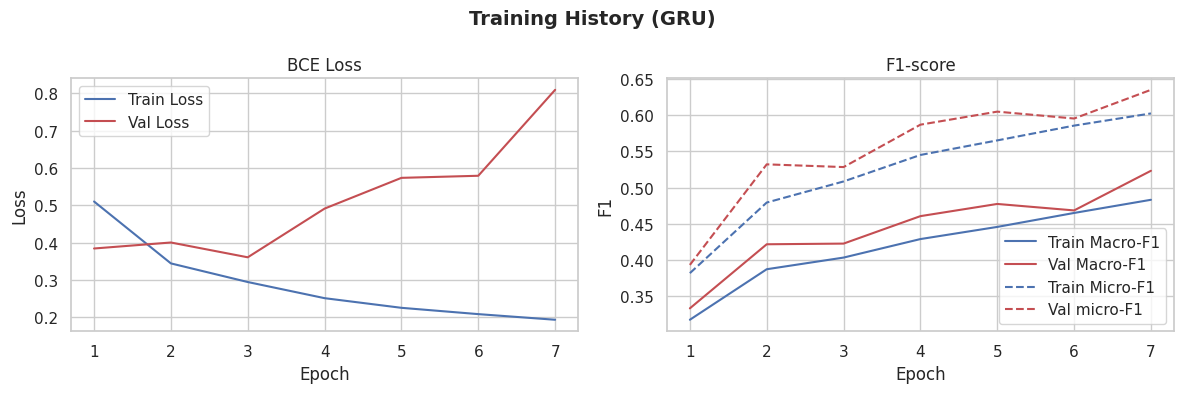

In [25]:
# ============================================================
# IF PRE-SAVED MODEL EXISTS, LOAD AND PLOT
# ============================================================

if os.path.exists(MODEL_PATH):

    # Load pre-saved model
    print(f"File '{MODEL_PATH}' found. Restoring...")
    model, labels, checkpoint = load_trained_model(MODEL_PATH, device)

    # Plot pre-saved history
    model_config = checkpoint.get('model_config', {})
    model_type = model_config.get('model_type', 'RNN')

    if 'weights_history' in checkpoint and 'history' in checkpoint['weights_history']:
        plot_history(checkpoint['weights_history']['history'],
                     title = f'Training History (GRU)')
    else:
        print("No valid data 'history' found in checkpoint.")


else:

# ============================================================
# IF NO PRE-SAVED MODEL EXISTS START OPTIMISATION
# ============================================================

    print(f"No file found at '{MODEL_PATH}'. Starting optimisation...")

    # Define additional, more aggressive pruner to speed optimisation
    pruner = optuna.pruners.MedianPruner(n_startup_trials = 5,
                                         n_warmup_steps = 2,
                                         interval_steps = 1)

    study = optuna.create_study(direction = 'maximize',
                                study_name = 'Toxic_RNN_Optimisation',
                                pruner = pruner)
    study.optimize(objective, n_trials = 20, show_progress_bar = True)

    print(f"\nSearch completed! The model with the best parameters has been saved in '{MODEL_PATH}'.")
    print('Best parameters:', study.best_params)
    print('Best validation macro-F1:', study.best_value)

    # Load trained model
    model, labels, checkpoint = load_trained_model(MODEL_PATH, device)

    # Plot history
    model_config = checkpoint.get('model_config', {})
    model_type = model_config.get('model_type', 'RNN')

    if 'weights_history' in checkpoint and 'history' in checkpoint['weights_history']:
        plot_history(checkpoint['weights_history']['history'],
                     title = f'Training History (GRU)')
    else:
        print("No valid data 'history' found in checkpoint.")

Ora eseguiamo un'ulteriore ottimizzazione, ovvero quella della soglia per la conversione dei logits in predizioni. Essendo il dataset estremamente sbilanciato su alcune label, infatti, una soglia fissa di probabilità impostata a 0.5 può penalizzare l'F1-score per quelle label. Pertanto, implementeremo un processo di ottimizzazione della soglia da considerare per ciascuna label. Quest'ottimizzazione viene eseguita esclusivamente sul **validation set**.

In [26]:
# ============================================================
# THRESHOLD OPTIMISATION PER LABEL ON VALIDATION SET
# ============================================================

print('\nOptimising thresholds on validation set...')

model.eval()
val_probs = []
val_targets = []

with torch.no_grad():
    for batch_x, batch_y in val_loader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)

        # Calculate probabilities with sigmoid, without applying >= .5 threshold
        val_probs.append(torch.sigmoid(logits).cpu().numpy())
        val_targets.append(batch_y.numpy())

val_probs = np.vstack(val_probs)
val_targets = np.vstack(val_targets)

best_thresholds = []

for i, label in enumerate(labels):

    # Calculate precision-recall curve for each label
    precision, recall, thresholds = precision_recall_curve(val_targets[:, i], val_probs[:, i])

    # precision_recall_curve returns one more precision/recall point
    # than thresholds, so compare only precision[:-1]/recall[:-1].
    if len(thresholds) == 0:
        best_thresh = 0.5
        best_label_f1 = 0.0
    else:
        # Calculate F1-score for each threshold
        f1_scores = (2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12))

        # Find threshold which maximises F1-score
        best_idx = int(np.nanargmax(f1_scores))
        best_thresh = float(thresholds[best_idx])
        best_label_f1 = float(f1_scores[best_idx])

    best_thresholds.append(best_thresh)

    print(f'{label:15s}: threshold = {best_thresh:.4f}, '
          f'validation F1-score = {best_label_f1:.4f}')

print('\nOptimised thresholds:', best_thresholds)


def apply_thresholds(probabilities, thresholds):
    return (probabilities >= np.asarray(thresholds)).astype(int)


# ----- VALIDATION COMPARISON -----
val_preds_default = (val_probs >= .5).astype(int)
val_preds_custom = apply_thresholds(val_probs, best_thresholds)

default_metrics = calculate_multilabel_metrics(val_targets, val_preds_default)
custom_metrics = calculate_multilabel_metrics(val_targets, val_preds_custom)

print('\nValidation metrics:')
print('Default 0.5:', default_metrics)
print('Optimised:  ', custom_metrics)


Optimising thresholds on validation set...
toxic          : threshold = 0.8401, validation F1-score = 0.7925
severe_toxic   : threshold = 0.9684, validation F1-score = 0.4953
obscene        : threshold = 0.9207, validation F1-score = 0.8193
threat         : threshold = 0.9913, validation F1-score = 0.5912
insult         : threshold = 0.9015, validation F1-score = 0.7279
identity_hate  : threshold = 0.9693, validation F1-score = 0.5122

Optimised thresholds: [0.8401371240615845, 0.9684296250343323, 0.9206615686416626, 0.9913322329521179, 0.9014843106269836, 0.9692527055740356]

Validation metrics:
Default 0.5: {'macro_f1': 0.5232554863413164, 'micro_f1': 0.6348717261705406, 'weighted_f1': 0.6595330791932817, 'macro_precision': 0.3915082781716284, 'macro_recall': 0.8708958746699725, 'exact_match_accuracy': 0.864764371657754, 'hamming_loss': 0.03795538101604278}
Optimised:   {'macro_f1': 0.6564019617331608, 'micro_f1': 0.7538706953176316, 'weighted_f1': 0.7569295773374398, 'macro_precisi

Infine, procediamo con la valutazione finale del modello, usando le soglie ottimizzate, sul **test set**.


================ FINAL TEST RESULTS ================
macro_f1                 : 0.6449
micro_f1                 : 0.7476
weighted_f1              : 0.7507
macro_precision          : 0.6124
macro_recall             : 0.6852
exact_match_accuracy     : 0.9142
hamming_loss             : 0.0190

Per-label classification report:
               precision    recall  f1-score   support

        toxic     0.7931    0.7820    0.7875      2294
 severe_toxic     0.4469    0.5816    0.5055       239
      obscene     0.8062    0.8202    0.8131      1268
       threat     0.4737    0.6250    0.5389        72
       insult     0.6798    0.7621    0.7186      1181
identity_hate     0.4750    0.5403    0.5055       211

    micro avg     0.7302    0.7658    0.7476      5265
    macro avg     0.6124    0.6852    0.6449      5265
 weighted avg     0.7380    0.7658    0.7507      5265
  samples avg     0.0640    0.0706    0.0643      5265



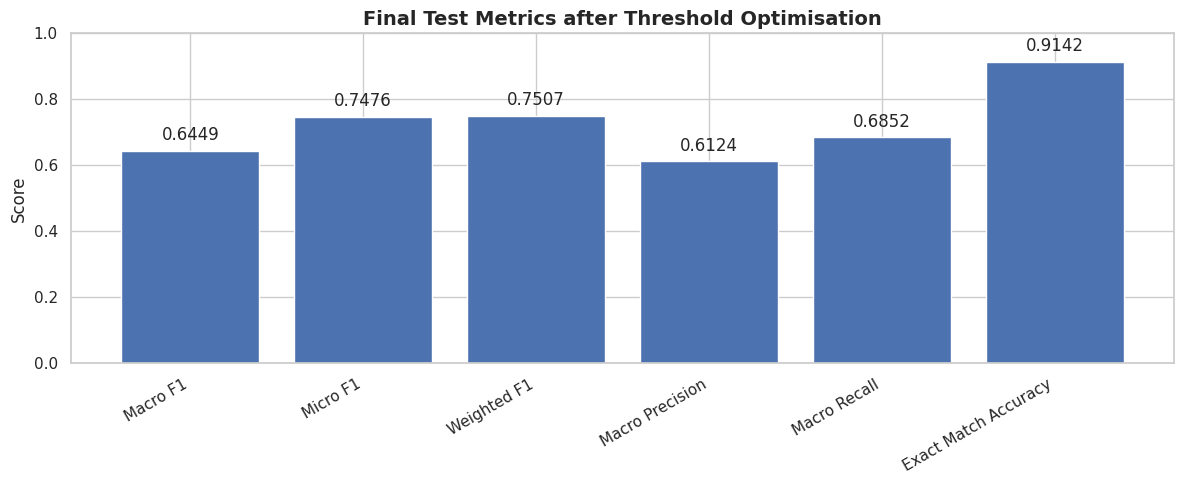

In [27]:
# ============================================================
# FINAL EVALUATION ON TEST SET
# ============================================================

test_probs = []
test_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)

        # Apply sigmoid to obtain test probabilities
        test_probs.append(torch.sigmoid(logits).cpu().numpy())
        test_targets.append(batch_y.numpy())

# Obtain test predictions
test_probs = np.vstack(test_probs)
test_targets = np.vstack(test_targets)
test_preds = apply_thresholds(test_probs, best_thresholds)

# Calculate test loss and metrics
test_metrics = calculate_multilabel_metrics(test_targets, test_preds)

print('\n================ FINAL TEST RESULTS ================')
for metric_name, value in test_metrics.items():
    print(f'{metric_name:25s}: {value:.4f}')

print('\nPer-label classification report:')
print(classification_report(test_targets,
                            test_preds,
                            target_names = labels,
                            zero_division = 0,
                            digits = 4)
                            )


# ============================================================
# FINAL METRICS PLOT AFTER THRESHOLD OPTIMISATION
# ============================================================

metrics_to_plot = {
    'Macro F1': test_metrics['macro_f1'],
    'Micro F1': test_metrics['micro_f1'],
    'Weighted F1': test_metrics['weighted_f1'],
    'Macro Precision': test_metrics['macro_precision'],
    'Macro Recall': test_metrics['macro_recall'],
    'Exact Match Accuracy': test_metrics['exact_match_accuracy']
    }

plt.figure(figsize = (12, 5))

bars = plt.bar(metrics_to_plot.keys(), metrics_to_plot.values())

plt.title('Final Test Metrics after Threshold Optimisation',
          fontsize = 14, fontweight = 'bold')
plt.ylabel('Score')
plt.xticks(rotation = 30, ha = 'right')
plt.ylim(0, 1)

# Values above bars
for bar, value in zip(bars, metrics_to_plot.values()):
    plt.text(bar.get_x() + bar.get_width() / 2,
             value + .02,
             f'{value:.4f}',
             ha = 'center',
             va = 'bottom')

plt.tight_layout()
plt.savefig('final_test_metrics.png')
plt.show()

### 3.3. Inferenza

Definiamo ora due funzioni: la prima funzione ha l'obiettivo di pulire le stringhe di testo dei commenti e convertirle in tensori da fornire al modello. La seconda funzione ha l'obiettivo di prendere questi tensori in input e ritornare una previsione sulla tossicità del commento.

In [28]:
def preprocess_text(text, vocab, MAX_LEN, unk_token = '<UNK>', pad_token = '<PAD>'):

    """
    This function cleans, tokenises and converts a string to a PyTorch tensor.
    """

    # 1. Clean text
    cleaned_text = clean_text(text)

    # 2. Tokenise
    tokens = cleaned_text.split()

    # 3. Encode
    unk_idx = vocab.get(unk_token, 1)
    pad_idx = vocab.get(pad_token, 0)
    indices = [vocab.get(token, unk_idx) for token in tokens]

    # 4. Padding / Truncation
    if len(indices) > MAX_LEN:
        indices = indices[: MAX_LEN]
    else:
        indices = indices + [pad_idx] * (MAX_LEN - len(indices))

    # 5. Convert to tensor
    tensor_input = torch.tensor(indices, dtype = torch.long).unsqueeze(0)

    return tensor_input

In [29]:
def predict_toxicity(text, model, vocab, labels, device, MAX_LEN, thresholds):

    """
    This function infers on a single text in input and calculate the probability
    for toxicity in the text, returning a 6-element binary vector.
    """

    model.eval()

    # 1. Preprocessing
    tensor = preprocess_text(text, vocab, MAX_LEN).to(device)

    # 2. Inference
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits).squeeze().cpu().numpy()

    # 3. Result formatting
    thresholds_array = np.array(thresholds)
    result_vector = (probs >= thresholds_array).astype(int).tolist()

    return result_vector

Chiamiamo ora quest'ultima funzione per eseguire le previsioni. Iniziamo con dei commenti di prova.

In [30]:
test_comment_1 = 'Are you kidding me? That is amazing!'
test_comment_1

'Are you kidding me? That is amazing!'

In [31]:
output_vector_1 = predict_toxicity(test_comment_1, model, vocab, labels, device, MAX_LEN, thresholds = best_thresholds)
output_vector_1

[0, 0, 0, 0, 0, 0]

In [32]:
test_comment_2 = 'Are you fucking kidding me?? I will kill you, faggot.'
test_comment_2

'Are you fucking kidding me?? I will kill you, faggot.'

In [33]:
output_vector_2 = predict_toxicity(test_comment_2, model, vocab, labels, device, MAX_LEN, thresholds = best_thresholds)
output_vector_2

[1, 1, 1, 1, 1, 1]

I due commenti di prova risultano classificati correttamente, in quanto dal primo viene restituito un vettore contenente solamente zeri, mentre dal secondo viene restituito un vettore con valore 1 per tutte le label, ad eccezione della label *threat* (minaccia).

Possiamo finalmente applicare la funzione di predizione all'intero dataset, per classificare tutti i commenti. Poiché, però, il dataset consiste in circa 160.000 righe, corrispondenti ad altrettanti commenti, anziché applicare la funzione riga per riga, sfrutteremo nuovamente le classi **Dataset** e **DataLoader** di PyTorch, che abbiamo usato in fase di preprocessing, per chiamare la funzione e fare quindi inferenza su batch di dati.

Definiamo innanzitutto la classe Dataset.

In [34]:
class ToxicInferenceDataset(Dataset):
    def __init__(self, texts, vocab, max_len, unk_token = '<UNK>', pad_token = '<PAD>'):
        self.texts = texts
        self.vocab = vocab
        self.max_len = max_len
        self.unk_token = unk_token
        self.pad_token = pad_token

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])

        # 1. Clean text
        cleaned_text = clean_text(text)

        # 2. Tokenise
        tokens = cleaned_text.split()

        # 3. Encode
        unk_idx = self.vocab.get(self.unk_token, 1)
        pad_idx = self.vocab.get(self.pad_token, 0)
        indices = [self.vocab.get(token, unk_idx) for token in tokens]

        # 4. Padding / Truncation
        if len(indices) > self.max_len:
            indices = indices[: self.max_len]
        else:
            indices = indices + [pad_idx] * (self.max_len - len(indices))


        return torch.tensor(indices, dtype = torch.long)

Ora definiamo i parametri per l'inferenza, istanziamo la classe e creiamo il DataLoader.

In [35]:
thresholds_array = np.array(best_thresholds)

# 1. Create Dataset and DataLoader
inference_ds = ToxicInferenceDataset(df['comment_text'].values, vocab, MAX_LEN)
inference_loader = DataLoader(inference_ds, batch_size = BATCH_SIZE, shuffle = False)

# 2. Inference cycle
model.eval()
all_predictions = []

print(f'Starting inference on {len(df)} comments in batches of size {BATCH_SIZE}...')

with torch.no_grad():
    for batch_x in inference_loader:

        batch_x = batch_x.to(device)

        # Calculate probabilities
        logits = model(batch_x)
        probs = torch.sigmoid(logits).cpu().numpy()

        # Obtain predictions of current batch using optimised thresholds
        batch_preds = (probs >= thresholds_array).astype(int).tolist()

        # Save predictions
        all_predictions.extend(batch_preds)

print('Inference completed!')

Starting inference on 159571 comments in batches of size 256...
Inference completed!


Per concludere, visualizziamo le predizioni del modello aggiungendo una colonna dedicata al DataFrame originale.

In [36]:
# Add predictions under a new column in the original DataFrame
df['predictions'] = all_predictions
display(df[['comment_text', 'predictions']].head(20))

,comment_text,predictions
0,Explanation\nWhy the edits made under my usern...,"[0, 0, 0, 0, 0, 0]"
1,D'aww! He matches this background colour I'm s...,"[0, 0, 0, 0, 0, 0]"
2,"Hey man, I'm really not trying to edit war. It...","[0, 0, 0, 0, 0, 0]"
3,"""\nMore\nI can't make any real suggestions on ...","[0, 0, 0, 0, 0, 0]"
4,"You, sir, are my hero. Any chance you remember...","[0, 0, 0, 0, 0, 0]"
5,"""\n\nCongratulations from me as well, use the ...","[0, 0, 0, 0, 0, 0]"
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,"[1, 0, 1, 0, 1, 0]"
7,Your vandalism to the Matt Shirvington article...,"[0, 0, 0, 0, 0, 0]"
8,Sorry if the word 'nonsense' was offensive to ...,"[0, 0, 0, 0, 0, 0]"
9,alignment on this subject and which are contra...,"[0, 0, 0, 0, 0, 0]"


## 4. Conclusioni

Visualizziamo nuovamente le metriche risultanti dal test finale.

In [37]:
print('\n================ FINAL TEST RESULTS ================')
for metric_name, value in test_metrics.items():
    print(f'{metric_name:25s}: {value:.4f}')

print('\nPer-label classification report:')
print(classification_report(test_targets,
                            test_preds,
                            target_names = labels,
                            zero_division = 0,
                            digits = 4)
                            )


================ FINAL TEST RESULTS ================
macro_f1                 : 0.6449
micro_f1                 : 0.7476
weighted_f1              : 0.7507
macro_precision          : 0.6124
macro_recall             : 0.6852
exact_match_accuracy     : 0.9142
hamming_loss             : 0.0190

Per-label classification report:
               precision    recall  f1-score   support

        toxic     0.7931    0.7820    0.7875      2294
 severe_toxic     0.4469    0.5816    0.5055       239
      obscene     0.8062    0.8202    0.8131      1268
       threat     0.4737    0.6250    0.5389        72
       insult     0.6798    0.7621    0.7186      1181
identity_hate     0.4750    0.5403    0.5055       211

    micro avg     0.7302    0.7658    0.7476      5265
    macro avg     0.6124    0.6852    0.6449      5265
 weighted avg     0.7380    0.7658    0.7507      5265
  samples avg     0.0640    0.0706    0.0643      5265



Il **macro-F1** calcola l'F1 di ciascuna delle 6 etichette e poi ne fa la media aritmetica, dando quindi lo stesso peso, per esempio, a *toxic* e a *threat*, nonostante abbiano frequenze molto diverse all'interno del dataset. Pertanto, il valore ottenuto di circa 0.64 indica che il modello ha una capacità complessiva discreta di riconoscere le diverse forme di tossicità, ma che esiste comunque una forte differenza tra le categorie.

Ciò risulta evidente nel **classification report**, dal quale si evince la differenza nei risultati per le varie label. In particolare, il modello funziona molto bene su *obscene* e *toxic* e abbastanza bene su *insult*, ovvero le tre etichette maggiormente presenti nel dataset, mentre è nettamente più debole sulle tre categorie rare: *severe_toxic*, *threat* e *identity_hate*.

Il **micro-F1**, invece, aggrega globalmente tutti i true positive, false positive e false negative. Di conseguenza, le etichette più rappresentate all'interno del dataset hanno un'influenza molto maggiore sulla metrica, e dal momento che il modello funziona bene su di esse, il micro-F1, con un valore di circa 0.75, è più alto del macro-F1.

Per concludere gli F1-score, il **weighted-F1**, che modifica il macro-F1 per considerare lo sbilanciamento delle classi, ha valore di circa 0.75, quindi è quasi identico al micro-F1. Questo è coerente con la distribuzione delle classi, in quanto le etichette più rappresentate contribuiscono maggiormente alka metrica.

Passando alla **precision** e alla **recall**, i valori risultanti sono rispettivamente di circa 0.61 e 0.69. Il modello, quindi, predilige la capacità di trovare tutte le classi positive, rispetto alla capacità di non classificare erroneamente un'etichetta come positiva. Si tratta, dunque, di un comportamento meno conservativo.

L'**exact-match accuracy** di 0.91, invece, indica un'alta percentuale di commenti per i quali tutte e 6 le etichette vengono assegnate correttamente. Nonostante quest'ottimo risultato sia probabilmente da imputare alla stragrande maggioranza di commenti neutri nel dataset, ciò è comunque positivo perché significa che i commenti neutri difficilmente vengono bloccati erroneamente.

Infine, la **hamming loss**, ovvero la frazione di etichette predette in maniera errata, è di circa 0.019, quindi un ottimo risultato.

Per concludere, complessivamente il modello commette pochi errori sulle singole etichette e si comporta molto bene con le etichette maggiormente rappresentate, ma risulta problematico nell'identificare le etichette più rare. Un esperimento potrebbe essere quello di abilitare l'undersampling del dataset per provare a bilanciare maggiormente le classi, nonostante ciò comporti perdita di informazione.